In [122]:
words = open('names.txt', 'r').read().splitlines()

print(words[:10])
print(len(words))
print(min(len(w) for w in words))
print(max(len(w) for w in words))

['emma', 'olivia', 'ava', 'isabella', 'sophia', 'charlotte', 'mia', 'amelia', 'harper', 'evelyn']
32033
2
15


In [123]:
# building the bigram
b = {}
for w in words:
    chs = ['<S>'] + list(w) + ['<E>']
    for ch1, ch2 in zip(chs, chs[1:]):
        bigram = (ch1, ch2)
        if bigram not in b:
            b[bigram] = 0
        b[bigram] += 1

b
sorted(b.items(), key=lambda x: -x[1])
sorted(b.items(), key=lambda x: x[1])

[(('q', 'r'), 1),
 (('d', 'z'), 1),
 (('p', 'j'), 1),
 (('q', 'l'), 1),
 (('p', 'f'), 1),
 (('q', 'e'), 1),
 (('b', 'c'), 1),
 (('c', 'd'), 1),
 (('m', 'f'), 1),
 (('p', 'n'), 1),
 (('w', 'b'), 1),
 (('p', 'c'), 1),
 (('h', 'p'), 1),
 (('f', 'h'), 1),
 (('b', 'j'), 1),
 (('f', 'g'), 1),
 (('z', 'g'), 1),
 (('c', 'p'), 1),
 (('p', 'k'), 1),
 (('p', 'm'), 1),
 (('x', 'n'), 1),
 (('s', 'q'), 1),
 (('k', 'f'), 1),
 (('m', 'k'), 1),
 (('x', 'h'), 1),
 (('g', 'f'), 1),
 (('v', 'b'), 1),
 (('j', 'p'), 1),
 (('g', 'z'), 1),
 (('v', 'd'), 1),
 (('d', 'b'), 1),
 (('v', 'h'), 1),
 (('h', 'h'), 1),
 (('g', 'v'), 1),
 (('d', 'q'), 1),
 (('x', 'b'), 1),
 (('w', 'z'), 1),
 (('h', 'q'), 1),
 (('j', 'b'), 1),
 (('x', 'm'), 1),
 (('w', 'g'), 1),
 (('t', 'b'), 1),
 (('z', 'x'), 1),
 (('p', 'b'), 2),
 (('t', 'g'), 2),
 (('q', 's'), 2),
 (('t', 'x'), 2),
 (('f', 'k'), 2),
 (('b', 't'), 2),
 (('j', 'n'), 2),
 (('k', 'c'), 2),
 (('z', 'k'), 2),
 (('s', 'j'), 2),
 (('s', 'f'), 2),
 (('z', 'j'), 2),
 (('n', 'q

In [124]:
# building the bigram using a pytorch array
import torch

N = torch.zeros(27,27, dtype=torch.int32)

chars = sorted(list(set(''.join(words))))
stoi = {s:i+1 for i,s in enumerate(chars)}
stoi['.'] = 0

for w in words:
    chs = ['.'] + list(w) + ['.']
    for ch1, ch2 in zip(chs, chs[1:]):
        ix1 = stoi[ch1]
        ix2 = stoi[ch2]
        N[ix1, ix2] += 1

itos = {i:s for s,i in stoi.items()}

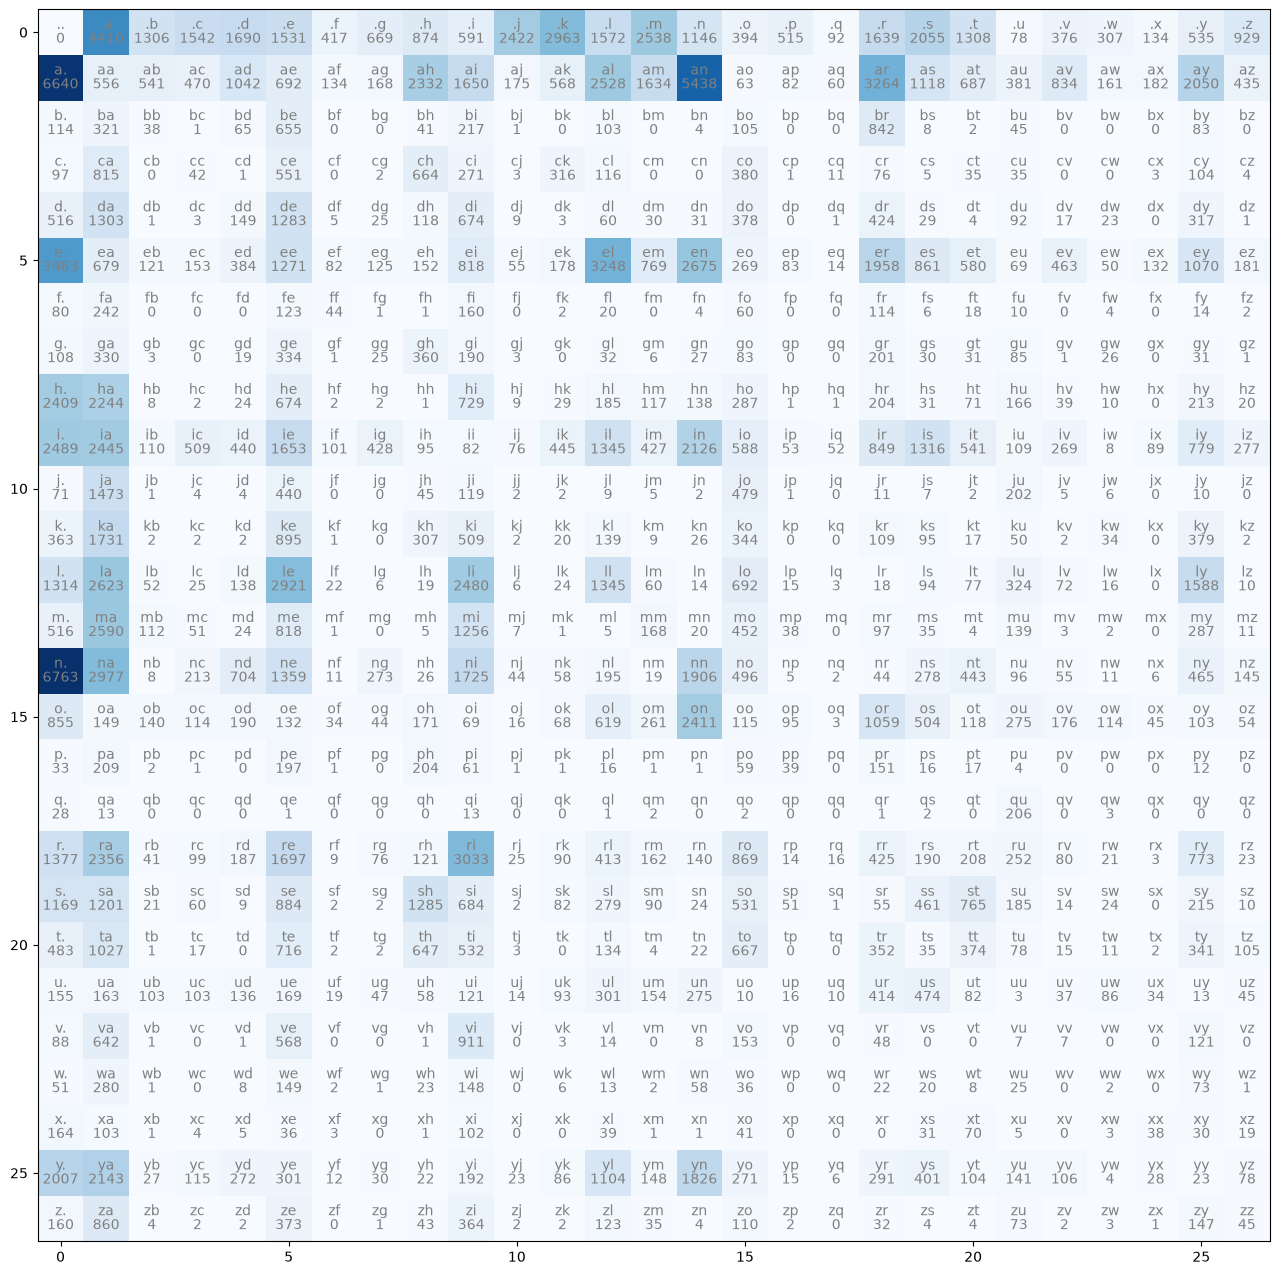

In [125]:
import matplotlib.pyplot as plt
%matplotlib inline

plt.figure(figsize=(16,16))
plt.imshow(N, cmap='Blues')
for i in range(27):
    for j in range(27):
        chstr = itos[i] + itos[j]
        plt.text(j, i, chstr, ha='center', va='bottom', color='gray')
        plt.text(j, i, N[i,j].item(), ha='center', va='top', color='gray')




In [199]:
P = (N+1).float() # adding one here to avoid -inf logs
P = P / P.sum(1, keepdim=True)

In [200]:
g = torch.Generator().manual_seed(2147483647)

for i in range(5):
    out = []
    ix = 0
    
    while True:
        p = P[ix]
        ix = torch.multinomial(p, num_samples=1, replacement=True, generator=g).item()
        out.append(itos[ix])
        if ix == 0:
            break
    print(''.join(out).replace('.', ''))
    # as seen, bigrams are not very good at generating names, but better than random.

cexze
momasurailezitynn
konimittain
llayn
ka


In [201]:
log_likelihood = 0.0
n = 0

for w in words:
    chs = ['.'] + list(w) + ['.']
    for ch1, ch2 in zip(chs, chs[1:]):
        ix1 = stoi[ch1]
        ix2 = stoi[ch2]
        prob = P[ix1, ix2]
        logprob = torch.log(prob)
        log_likelihood += logprob
        n += 1
        print(f"{ch1}{ch2}: {prob:.4f} {logprob:.4f}")

nll = -log_likelihood
print(f"{log_likelihood=}")
print(f"{nll=}")
print(f"{nll/n=}")


.e: 0.0478 -3.0410
em: 0.0377 -3.2793
mm: 0.0253 -3.6753
ma: 0.3885 -0.9454
a.: 0.1958 -1.6305
.o: 0.0123 -4.3965
ol: 0.0779 -2.5526
li: 0.1774 -1.7293
iv: 0.0152 -4.1845
vi: 0.3508 -1.0476
ia: 0.1380 -1.9807
a.: 0.1958 -1.6305
.a: 0.1376 -1.9835
av: 0.0246 -3.7041
va: 0.2473 -1.3971
a.: 0.1958 -1.6305
.i: 0.0185 -3.9919
is: 0.0743 -2.5998
sa: 0.1478 -1.9119
ab: 0.0160 -4.1363
be: 0.2455 -1.4044
el: 0.1589 -1.8396
ll: 0.0962 -2.3408
la: 0.1876 -1.6733
a.: 0.1958 -1.6305
.s: 0.0641 -2.7468
so: 0.0654 -2.7270
op: 0.0121 -4.4180
ph: 0.1947 -1.6364
hi: 0.0955 -2.3485
ia: 0.1380 -1.9807
a.: 0.1958 -1.6305
.c: 0.0481 -3.0339
ch: 0.1869 -1.6774
ha: 0.2937 -1.2251
ar: 0.0963 -2.3405
rl: 0.0325 -3.4256
lo: 0.0496 -3.0047
ot: 0.0149 -4.2032
tt: 0.0670 -2.7031
te: 0.1281 -2.0549
e.: 0.1948 -1.6357
.m: 0.0792 -2.5358
mi: 0.1885 -1.6687
ia: 0.1380 -1.9807
a.: 0.1958 -1.6305
.a: 0.1376 -1.9835
am: 0.0482 -3.0321
me: 0.1228 -2.0971
el: 0.1589 -1.8396
li: 0.1774 -1.7293
ia: 0.1380 -1.9807
a.: 0.1958 -

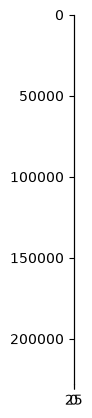

In [204]:
# creating the training set of bigrams(x, y)

xs, ys = [], []
for w in words:
    chs = ['.'] + list(w) + ['.']
    for ch1, ch2 in zip(chs, chs[1:]):
        ix1 = stoi[ch1]
        ix2 = stoi[ch2]
        xs.append(ix1)
        ys.append(ix2)

xs = torch.tensor(xs)
ys = torch.tensor(ys)
num = xs.nelement()

# one hot encoding: turn 13 into vectors of length 27, with all zeros except for a 1 at index 13
import torch.nn.functional as F
xenc = F.one_hot(xs, num_classes=27).float()
yenc = F.one_hot(ys, num_classes=27).float()
plt.imshow(xenc)


In [203]:
print(f"{nll/n=}")

for i in range(10):
    out = []
    ix = 0
    
    while True:
        p = P[ix]
        ix = torch.multinomial(p, num_samples=1, replacement=True, generator=g).item()
        out.append(itos[ix])
        if ix == 0:
            break
    print(''.join(out).replace('.', ''))

nll/n=tensor(2.4544)
s
t
a
ze
brylon
kymen
kaedeshaharigaybe
deyli
kotallinaler
d


In [205]:
W = torch.randn((27, 27), generator=g, requires_grad=True) # random initializes a weight matrix from normal distribution
xenc @ W # matrix multiplication, 1 column output for each row of xenc
(xenc @ W)[3, 13] # this is just a dot product, matmul is the way to do many of them in parallel
# (5, 27) @ (27, 27) --> (5, 27) 
# the 27 numbers are giving us log counts (logits)!! we'll exponentiate them --> softmax to get probabilities.

logits = xenc @ W 
counts = logits.exp()
probs = counts / counts.sum(1, keepdim=True)
probs.shape # all of these are differentiable operations --> can backprop thru these
# counts and probs line together are called 'softmax' --> exp than normalize, (-inf, inf)-->(0,1)

# this above together is a forward pass!
# W started at a random point, now we need to find its way down the valley!! --> tuning/gradient descent

# our neural net rn is a single linear layer + softmax. 

loss = -probs[torch.arange(5),ys].log().mean()
print(loss)

IndexError: shape mismatch: indexing tensors could not be broadcast together with shapes [5], [228146]

In [ ]:
#gradient descent
for i in range(1000):

    #forward pass
    xenc = F.one_hot(xs, num_classes=27).float()
    logits = xenc @ W 
    counts = logits.exp()
    probs = counts / counts.sum(1, keepdim=True)
    loss = -probs[torch.arange(num),ys].log().mean()
    print(loss.item())

    #backward pass
    W.grad = None #set grad to 0
    loss.backward()

    #update
    W.data += -50 * W.grad # tried diff alphas like 0.05, 0.1, 0.2, 10

    # regularization
    # add smth like + 0.01* W**2 to the loss --> works like a spring (loss function now tries to fit probs but also to push W to 0)
    

3.783329486846924
3.388772964477539
3.155073881149292
3.005793809890747
2.9061875343322754
2.8335397243499756
2.7793314456939697
2.738041639328003
2.7058918476104736
2.680326461791992
2.6595609188079834
2.6423404216766357
2.627800226211548
2.615344524383545
2.604548931121826
2.595099687576294
2.5867574214935303
2.579333543777466
2.572679281234741
2.5666751861572266
2.5612266063690186
2.5562567710876465
2.551703453063965
2.5475149154663086
2.5436489582061768
2.540069818496704
2.5367469787597656
2.5336544513702393
2.5307695865631104
2.5280721187591553
2.525545835494995
2.523174285888672
2.520944833755493
2.5188450813293457
2.51686429977417
2.5149924755096436
2.5132217407226562
2.5115442276000977
2.5099520683288574
2.508439779281616
2.5070016384124756
2.505631446838379
2.5043258666992188
2.503079652786255
2.5018885135650635
2.5007498264312744
2.499659776687622
2.498615264892578
2.4976134300231934
2.4966518878936768
2.4957282543182373
2.494840145111084
2.493986129760742
2.4931633472442627


In [212]:
print(loss)
for i in range(10):
    out = []
    ix = 0
    
    while True:
        p = P[ix]
        ix = torch.multinomial(p, num_samples=1, replacement=True, generator=g).item()
        out.append(itos[ix])
        if ix == 0:
            break
    print(''.join(out).replace('.', ''))

tensor(2.4553, grad_fn=<NegBackward0>)
xi
d
dor
khaphian
eon
s
ilele
jambrifu
e
mazany
